# Optimización y sensibilidad
Versión documentada el 26/10/2026: corpus simulado de 300 correos.
La selección y el diagnóstico usan 280/20; las versiones finales se ajustan con 10/100/200/300.
Los 25 de data/test no se usan en este notebook. La evaluación diagnóstica no demuestra generalización independiente de los modelos finales.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, project_path
from src.data_processing import load_data, split_data
config = load_config()
data = load_data(project_path(config["data_path"]))
train, test = split_data(data, config["test_size"], config["seed"], config["cv_folds"], holdout_manifest=project_path(config["holdout_manifest"]) if config.get("holdout_manifest") else None)


In [2]:
# Ejecutar una vez el experimento completo: python -m src.train
# Este notebook analiza resultados registrados sin volver a elegir por test.
grid = pd.read_csv(ROOT / "results/metrics/grid_search.csv")
display(grid.sort_values("rank_test_score").head())

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classifier__C,param_classifier__class_weight,param_tfidf__min_df,params,split0_test_score,split1_test_score,...,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,mean_train_score,std_train_score,family,param_classifier__estimator__C,param_classifier__estimator__class_weight
2,0.055399,0.004607,0.011415,0.001160,0.1,balanced,1,"{'classifier__C': 0.1, 'classifier__class_weig...",0.972470,0.971135,...,1,1.0,1.0,1.0,1.0,1.0,0.0,logistic,NaN,NaN
20,0.057119,0.008446,0.012522,0.001621,10.0,NaN,1,"{'classifier__estimator__C': 10.0, 'classifier...",0.986327,0.972944,...,1,1.0,1.0,1.0,1.0,1.0,0.0,svm,10.0,NaN
22,0.065173,0.001198,0.013235,0.000487,10.0,balanced,1,"{'classifier__estimator__C': 10.0, 'classifier...",0.986327,0.972944,...,1,1.0,1.0,1.0,1.0,1.0,0.0,svm,10.0,balanced
10,0.132197,0.013909,0.010993,0.000912,10.0,balanced,1,"{'classifier__C': 10.0, 'classifier__class_wei...",0.972470,0.957764,...,2,1.0,1.0,1.0,1.0,1.0,0.0,logistic,NaN,NaN
16,0.056699,0.005115,0.011539,0.002587,1.0,NaN,1,"{'classifier__estimator__C': 1.0, 'classifier_...",0.986327,0.972944,...,3,1.0,1.0,1.0,1.0,1.0,0.0,svm,1.0,NaN


In [3]:
from src.train import analyze_search
import json
summary = json.loads((ROOT / "results/metrics/training_summary.json").read_text(encoding="utf-8"))
ranking = analyze_search(grid[grid.family == summary["selected_family"]])
display(pd.DataFrame(ranking))

,hyperparameter,range_f1,marginal_means
0,param_classifier__C,0.005065,"{'0.1': 0.9563986167513032, '1.0': 0.961463266..."
1,param_tfidf__min_df,0.005011,"{'1': 0.9622464235473703, '2': 0.9572354226985..."
2,param_classifier__class_weight,0.001145,"{'balanced': 0.9603132842010446, 'none': 0.959..."


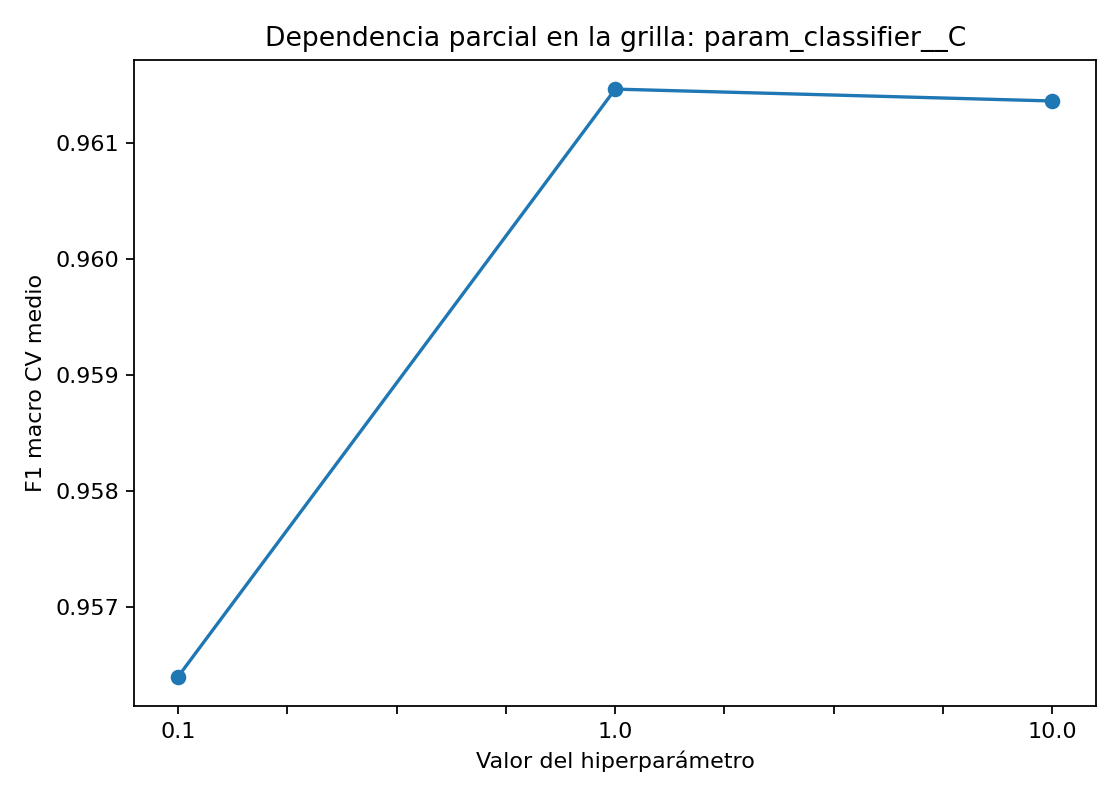

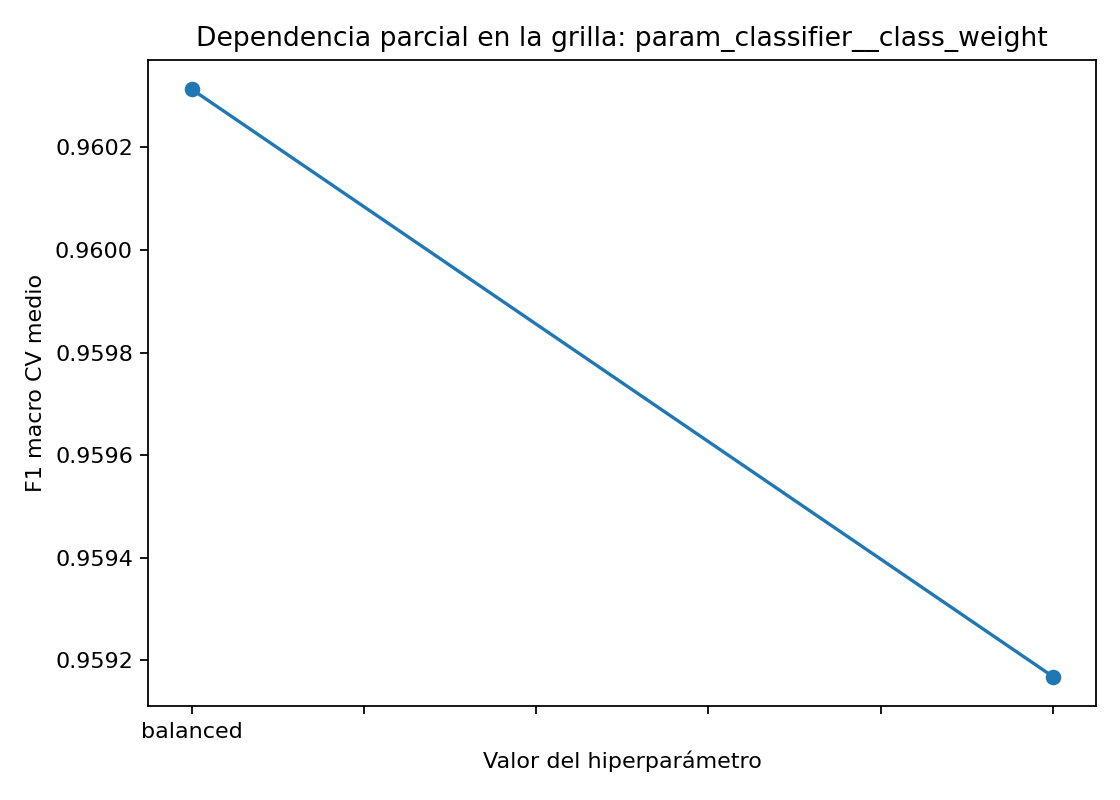

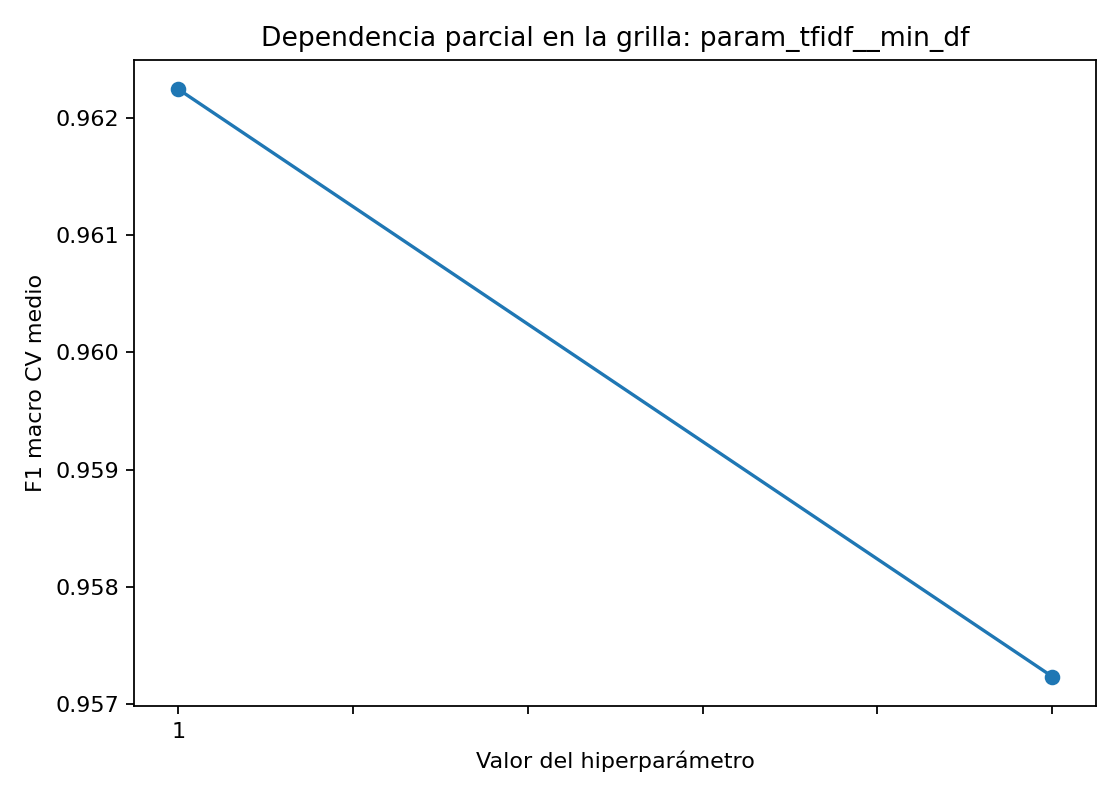

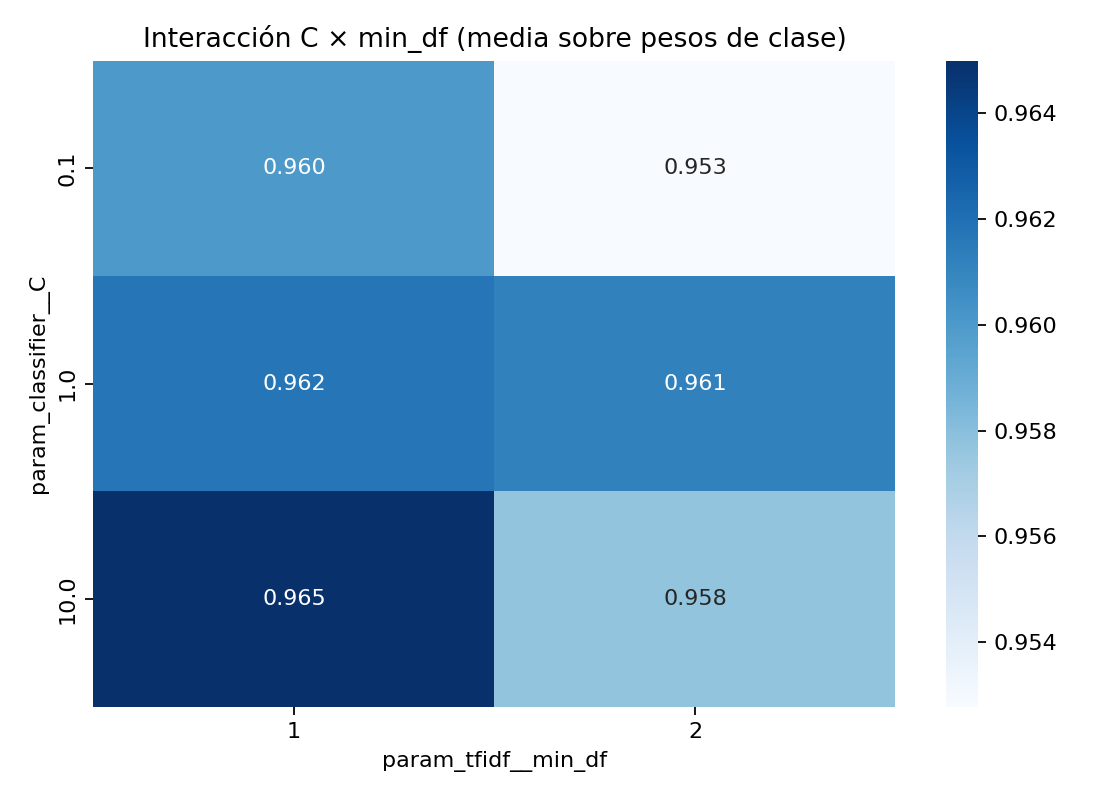

In [4]:
from IPython.display import Image, display
for path in sorted((ROOT / "documentacion/imagenes").glob("sensitivity*.png")):
    display(Image(filename=str(path)))
display(Image(filename=str(ROOT / "documentacion/imagenes/hyperparameter_interaction.png")))

## Workshop S5: PDP con modelo sustituto

Se ajusta RandomForestRegressor a las 12 configuraciones SVM y sus F1 CV.
No es otro clasificador de tickets ni modifica los cuatro .pkl. Se muestran PDP,
interacción e importancia por permutación y MDI. El ajuste es exploratorio: se
comprueba MAE/R² leave-one-out sobre las configuraciones, no sobre correos nuevos.

,parameter,mdi,permutation_mae_increase,permutation_std
0,min_df,0.403541,0.002172,0.000643
1,log10_C,0.539616,0.002160,0.000550
2,class_weight_balanced,0.056843,0.000206,0.000106


MAE LOO: 0.0023889416969995747 R² LOO: 0.4712392826195415


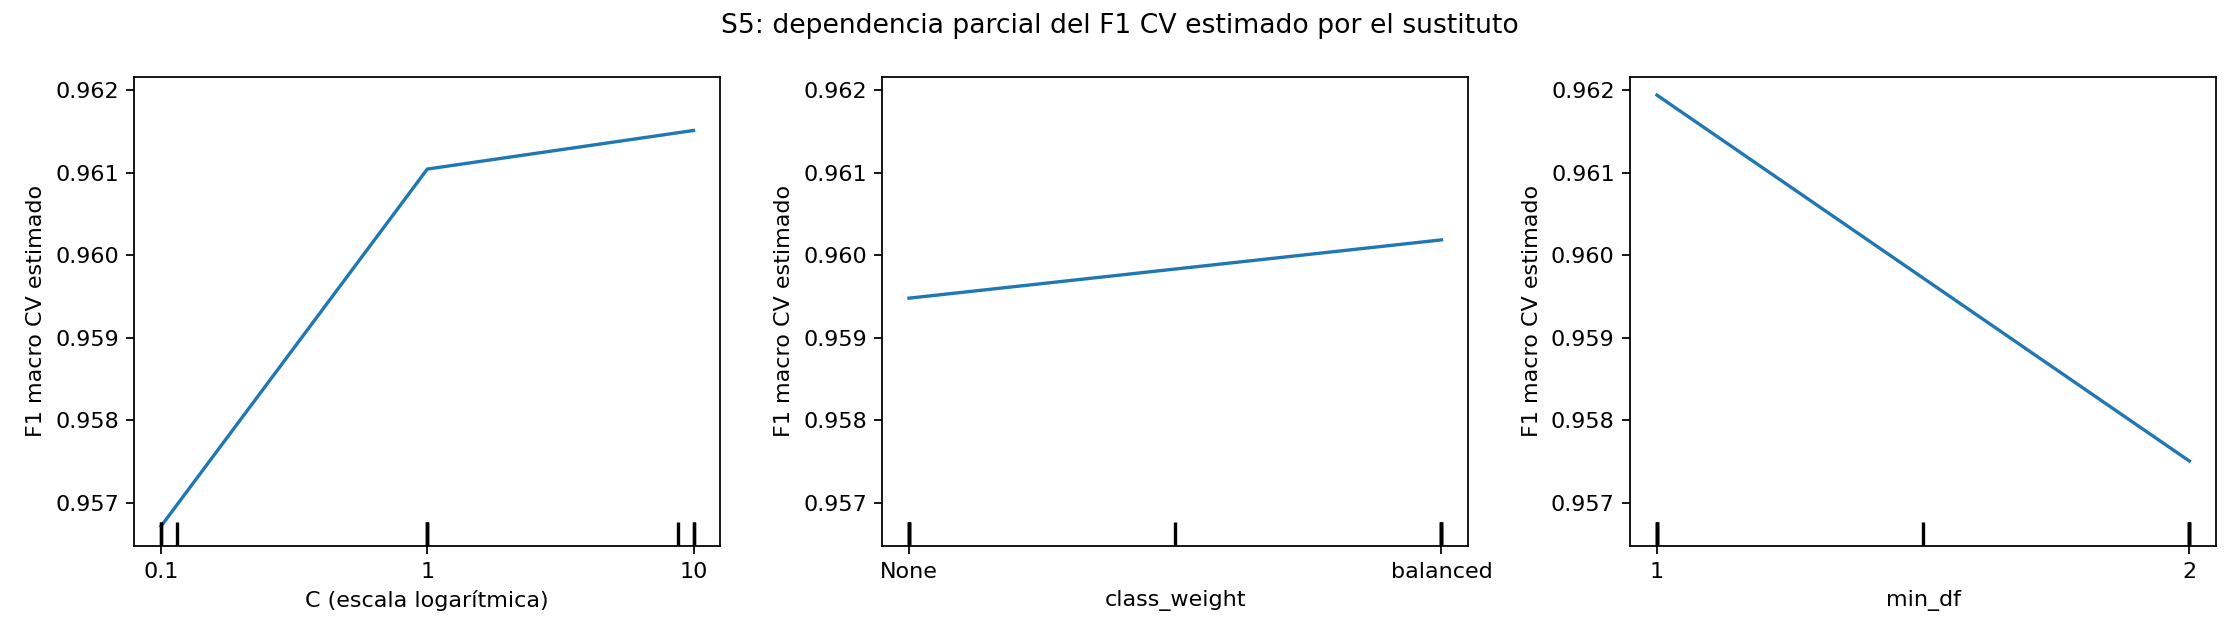

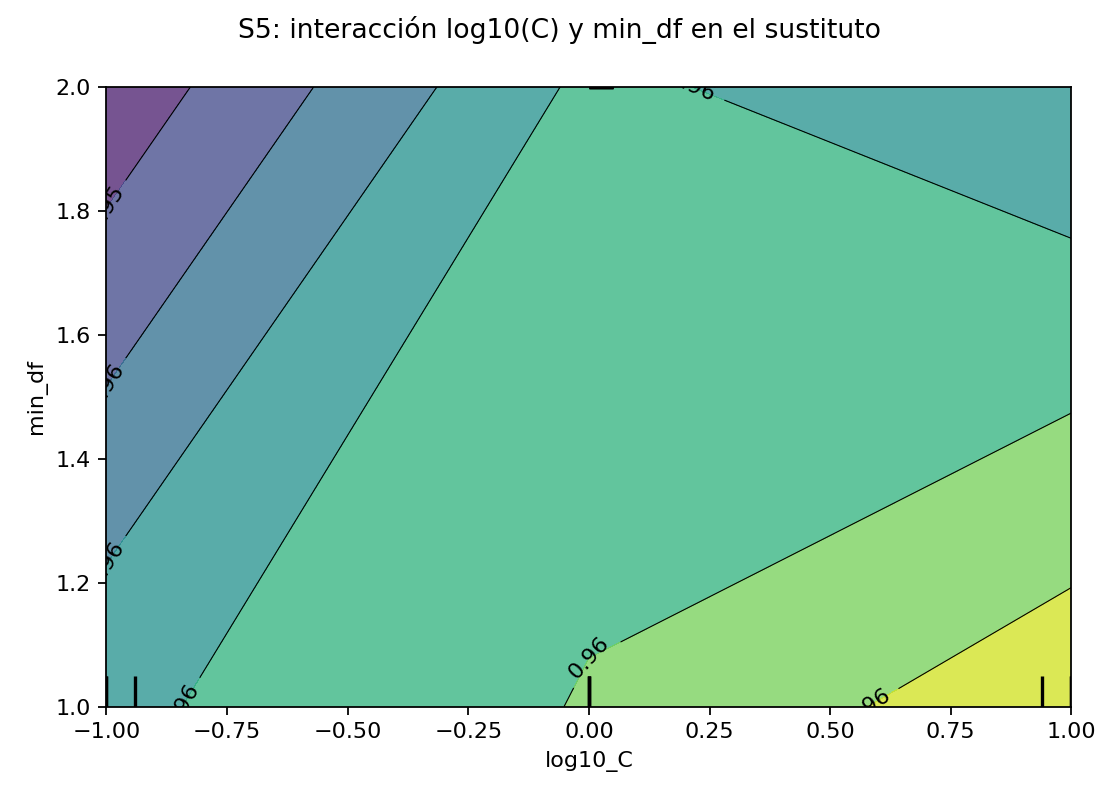

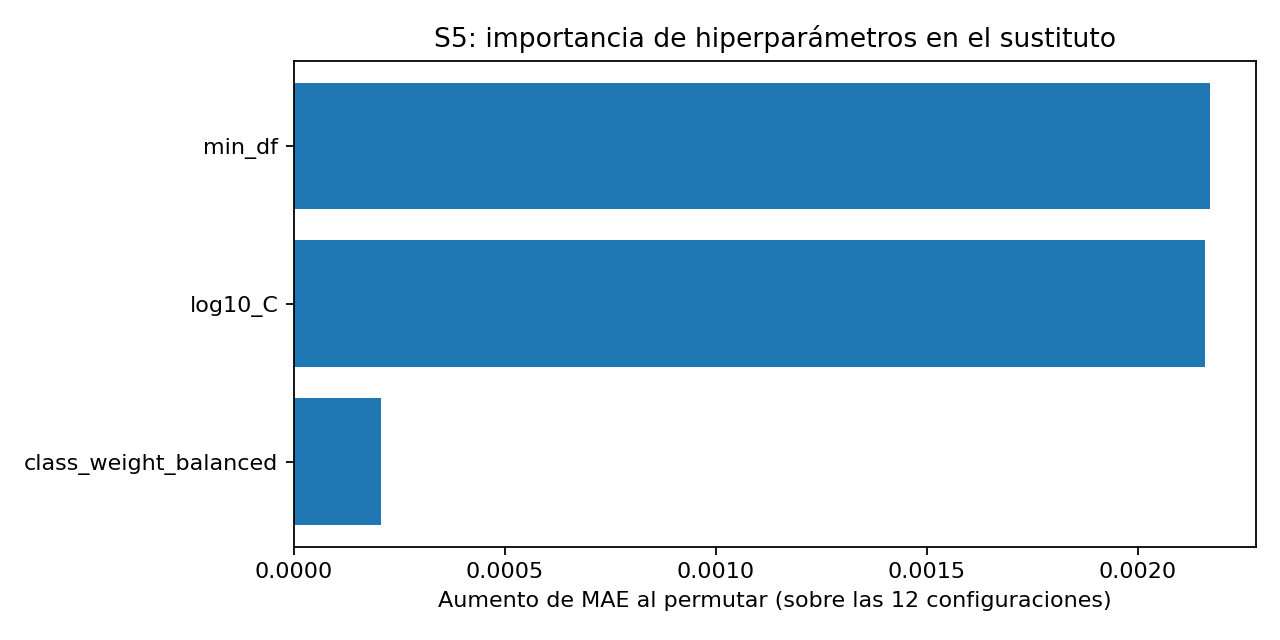

In [5]:
from src.optimization_analysis import analyze_saved_search
surrogate_report = analyze_saved_search(ROOT / "results/metrics/grid_search.csv", summary["selected_family"])
display(pd.DataFrame(surrogate_report["ranking"]))
print("MAE LOO:", surrogate_report["loo_mae"], "R² LOO:", surrogate_report["loo_r2"])
for name in ["s5_pdp_hiperparametros.png", "s5_pdp_interaccion.png", "s5_importancia_hiperparametros.png"]:
    display(Image(filename=str(ROOT / "documentacion/imagenes" / name)))
